## Coding Exercise #0404

Participantes: Manuel Ortega + Nicolas Vega + Nicolás Torres + Sebastián Escobar + German San Martín

### 1. Dimensional reduction with PCA:

In [8]:
# %pip install scikit-learn
import sklearn as sk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA, NMF
import os
%matplotlib inline

#### 1.1. Read in data and explore:

In [9]:
# Go to the directory where the data file is located.
# os.chdir(r'~~')                # Please, replace the path with your own.

In [10]:
df = pd.read_csv('data_number_nine.csv', header='infer')

In [11]:
df.shape

(23, 23)

In [12]:
df.head(5)

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,0.006,0.006,0.006,0.005,0.005,0.005,0.0050,0.005,0.0050,0.0050,...,0.0050,0.0050,0.0050,0.0050,0.0050,0.0050,0.0050,0.005,0.006,0.006
1,0.005,0.005,0.005,0.005,0.005,0.005,0.0050,0.005,0.0050,0.0050,...,0.0050,0.0050,0.0050,0.0050,0.0050,0.0050,0.0050,0.005,0.005,0.005
2,0.005,0.005,0.005,0.005,0.005,0.005,0.0050,0.005,0.0050,0.0050,...,0.7854,0.7776,0.3738,0.1486,0.0050,0.0050,0.0050,0.005,0.005,0.005
3,0.005,0.005,0.005,0.005,0.005,0.005,0.0050,0.005,0.1797,0.5951,...,0.9911,0.9911,0.9911,0.9756,0.8242,0.5912,0.0283,0.005,0.005,0.005
4,0.005,0.005,0.005,0.005,0.005,0.005,0.1836,0.599,0.9368,0.9911,...,0.5214,0.6099,0.7815,0.9911,0.8941,0.8785,0.4088,0.005,0.005,0.005


#### 1.2. Visualize the data:

In [13]:
# Define a suitable visualization function based on imshow().
# Visualizes the whole dataset at once as pixel image.
def ShowMe(X):
    Y= 1.0 - X
    plt.imshow(Y, cmap='gray')
    plt.show()

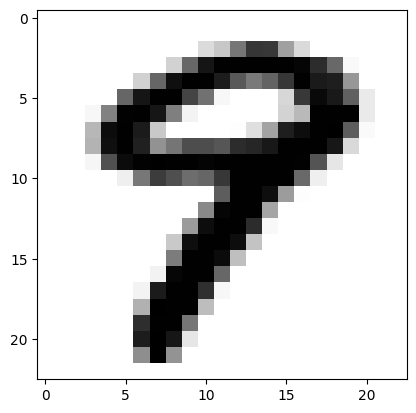

In [14]:
X = np.array(df)
ShowMe(X)

#### 1.3. Visualize the reduced dimensional input by PCA:

In [15]:
# Define a function that returns reduced dimensional input.
def reducedInputPCA(X, nPC):
    pca = PCA(nPC)                            # Define a PCA object for a given number of target PCs.
    X_pca = pca.fit_transform(X)              # Get the transformed scores.
    return pca.inverse_transform(X_pca)       # Bring back the transformed scores to the original coordinate system.

N# of PCs = 23


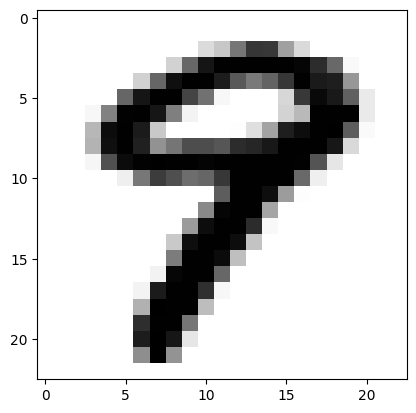

N# of PCs = 10


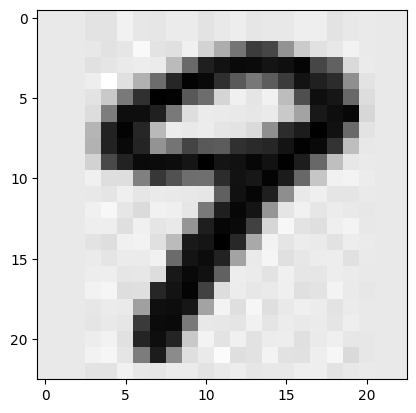

N# of PCs = 5


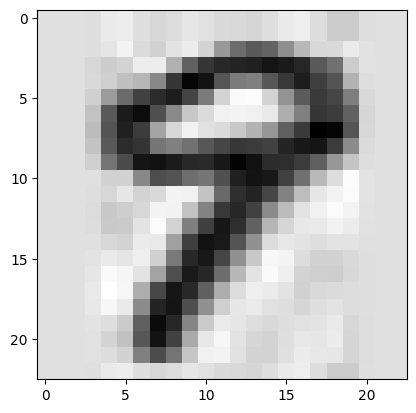

N# of PCs = 3


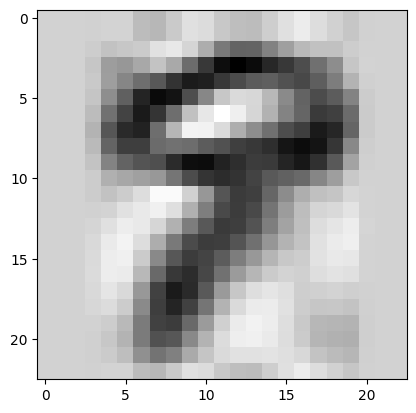

N# of PCs = 1


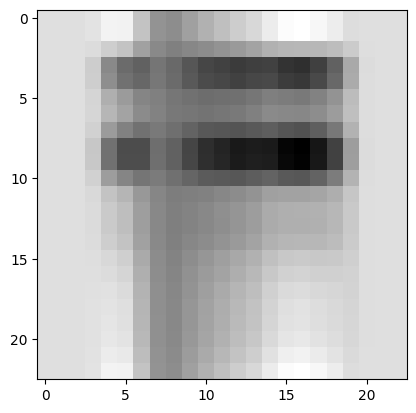

In [16]:
# Visualize the reduced dimensional input for different cases.
# As we shrink the dimension, the image gets less clear.
for nPC in [23, 10, 5, 3, 1]:
    Z = reducedInputPCA(X, nPC)
    print("N# of PCs =", nPC)
    ShowMe(Z)

#### 1.4. Analysis of the cumulative variance ratio (CVR):

In [17]:
pca = PCA(n_components=23)                          # Define a PCA object.
pca.fit(X)                                            # Train with the data.

PCA(n_components=23)

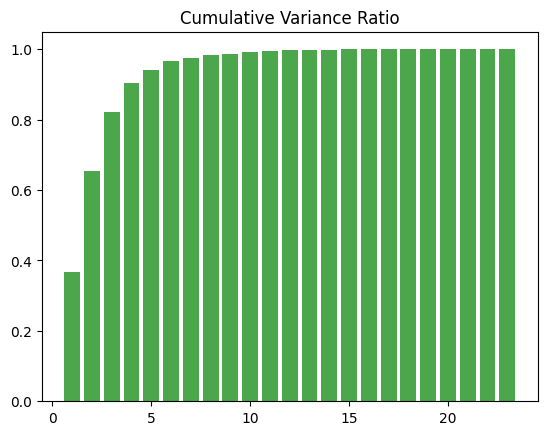

In [18]:
# Visualize the CVRs as a Barplot.
CVRs = np.cumsum(pca.explained_variance_ratio_)     # Calculate the CVRs.
nPCs = np.arange(23) + 1                            # Define an array that corresponds to the number of PCs.
plt.bar(nPCs, CVRs,color='green', alpha=0.7)
plt.title('Cumulative Variance Ratio')
plt.show()

### 2. Dimensional reduction with NMF:

NMF (Non-negative Matrix Factorization) is applicable for data matrix that contains only non-negative values.<br>
Similar to PCA, we can do dimensional reduction and obtain reduced dimensional input using NMF. <br>
We notice that we get a bit less 'noisy' images compared to the result of PCA.<br>
More information at [Wikipedia](https://en.wikipedia.org/wiki/Non-negative_matrix_factorization).

NMF es una tecnica de aprendizaje no supervisado que reduce la dimension de un conjunto de datos complejos descomponiendolos en componentes fundamentales mas simples.

Se expresa algebraicamente como:

$$V \approx W \times H$$

Donde cada componente algebraico representa:
* **$V$**: Es la matriz original de datos con dimensiones $m \times n$, donde $m$ representa el número de muestras (u objetos) y $n$ representa el número de variables (o características originales).
* **$W$**: Es la matriz de coeficientes, pesos o activaciones con dimensiones $m \times k$ (donde $k$ es el número de componentes reducido).
* **$H$**: Es la matriz de bases, componentes o lienzos con dimensiones $k \times n$, que representa las características fundamentales compartidas de los datos.
### La Norma Euclídea Matricial (Norma de Frobenius)

Para medir qué tan buena es nuestra aproximación $V \approx W \times H$, utilizamos la **norma euclídea matricial** (conocida matemáticamente como **Norma de Frobenius**).

* Es el equivalente al Error Cuadrático Medio (MSE) pero aplicado a matrices completas en lugar de vectores.
* Calcula la diferencia elemento por elemento entre la matriz original $V$ y la matriz reconstruida ($W \times H$), eleva cada una de esas diferencias al cuadrado, las suma todas y finalmente obtiene la raíz cuadrada:


En palabras sencillas, es una métrica que nos dice "qué tanta información o calidad perdimos" al desarmar y volver a armar nuestro lienzo. Mientras más cercano a cero sea este valor, más exacta y fiel será nuestra reconstrucción.

#### 2.1. Visualize the reduced dimensional input by NMF:

In [19]:
# Define a function that returns reduced dimensional input.
def reducedInputNMF(X, n):
    nmf = NMF(n_components=n, init='random', random_state=0, max_iter=10000)  # Define a NMF object for a given number of target components.
    X_nmf = nmf.fit_transform(X)                                  # Get the transformed scores.
    return nmf.inverse_transform(X_nmf)                           # Bring back the transformed scores to the original coordinate system.

N# of Components = 23


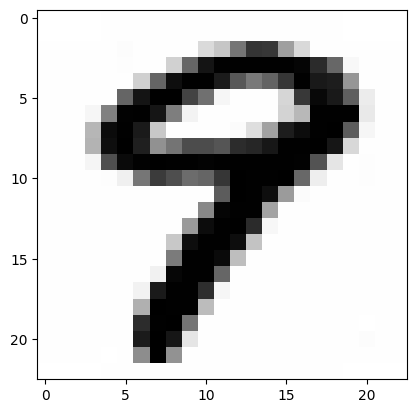

N# of Components = 10


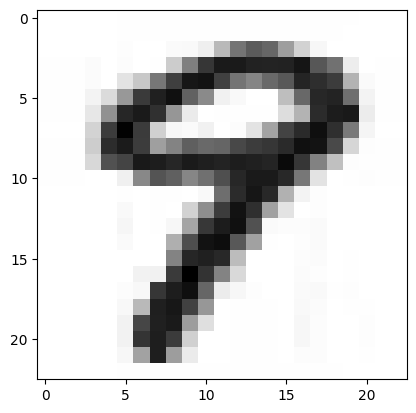

N# of Components = 5


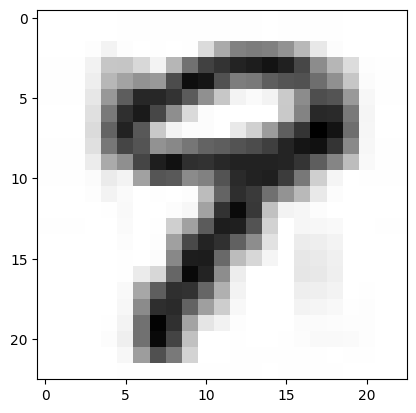

N# of Components = 3


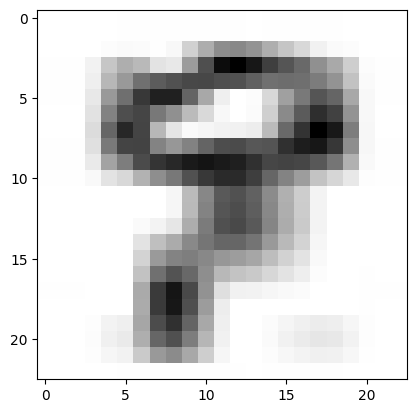

N# of Components = 1


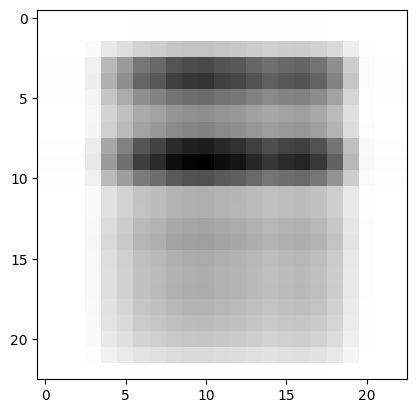

In [20]:
# Visualize the reduced dimensional input for different cases.
# As we shrink the dimension, the image gets less clear.
for n in [23, 10, 5, 3, 1]:
    Z = reducedInputNMF(X, n)
    print( "N# of Components =", n)
    ShowMe(Z)

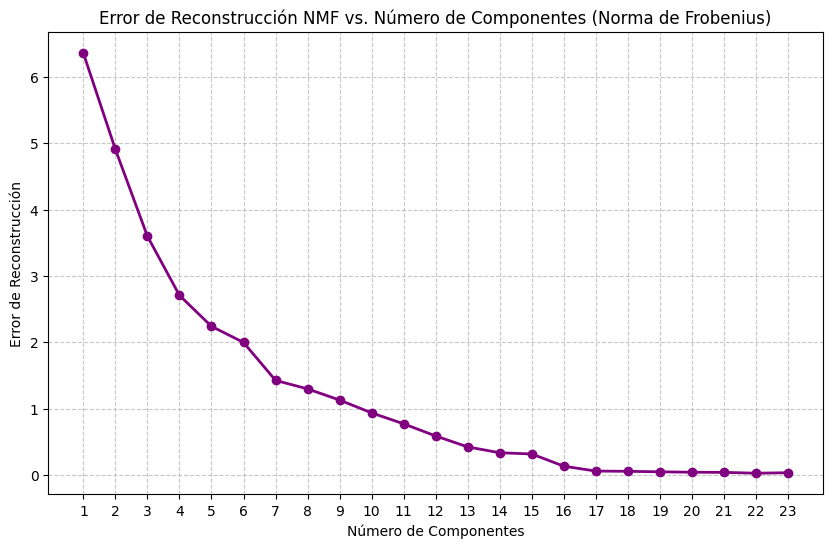

In [29]:
# Importar las librerías necesarias y cargar los datos originales de la imagen (df)
X_img = np.array(df)

# Probar diferentes números de componentes (de 1 a 23)
componentes = range(1, 24)
errores = []

for n in componentes:
    nmf = NMF(n_components=n, init='random', random_state=0, max_iter=10000)
    X_nmf = nmf.fit_transform(X_img)
    X_reconstructed = nmf.inverse_transform(X_nmf)
    # Calcular la Norma de Frobenius (error de reconstrucción)
    error = np.linalg.norm(X_img - X_reconstructed)
    errores.append(error)

# Graficar los errores de reconstrucción
plt.figure(figsize=(10, 6))
plt.plot(componentes, errores, marker='o', color='purple', linestyle='-', linewidth=2)
plt.title('Error de Reconstrucción NMF vs. Número de Componentes (Norma de Frobenius)')
plt.xlabel('Número de Componentes')
plt.ylabel('Error de Reconstrucción')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(componentes)
plt.show()

#### 2.2. Why is NMF less 'noisy'? PCA vs NMF side by side:
PCA can reconstruct pixels with **negative** values ("negative ink", marked in red), which shows up as the gray noise around the digit.<br>
NMF only adds non-negative parts, so this cannot happen: the background stays clean, even though its total error is a bit higher.

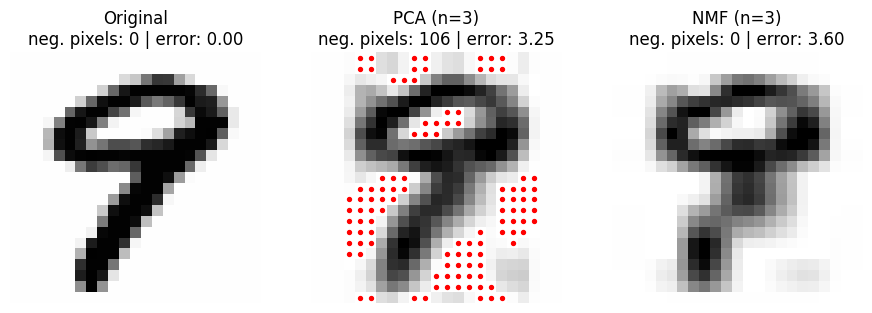

In [21]:
# Compare the original with PCA and NMF using the same number of components.
# Fixed color scale (vmin, vmax) so imshow() does not rescale away the negative values.
n = 3
images = {'Original': X, f'PCA (n={n})': reducedInputPCA(X, n), f'NMF (n={n})': reducedInputNMF(X, n)}

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, (title, Z) in zip(axes, images.items()):
    ax.imshow(1.0 - Z, cmap='gray', vmin=0, vmax=1)
    rows, cols = np.where(Z < 0)                      # Pixels with negative 'ink'.
    ax.scatter(cols, rows, c='red', s=8)
    error = np.linalg.norm(X - Z)                     # Reconstruction error (Frobenius norm).
    ax.set_title(f'{title}\nneg. pixels: {len(rows)} | error: {error:.2f}')
    ax.axis('off')
plt.show()

### 3. Optimized high dimensional visualization with PCA:

#### 3.1. Simulate data:

In [22]:
# 3 clusters in 8 dimensional space.
# Hard to visualize!
X, label = make_blobs(n_samples=150, n_features=8, centers=3, cluster_std=5, random_state=123)
X.shape

(150, 8)

In [23]:
# Define a custom color palette.
myColors = {0: 'red', 1: 'green', 2: 'blue'}
labelColors = pd.Series(label).apply(lambda x: myColors[x])

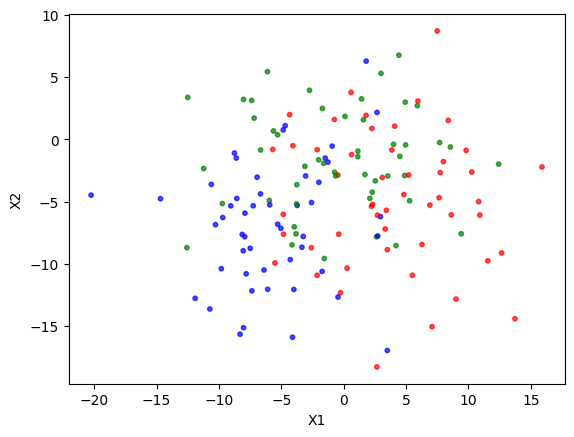

In [24]:
# Visualize on the X1 vs X2 plane. X1 ==> column 0,  X2 ==> column 1.
# We can hardly tell the clusters apart!
# The clusters largely overlap.
plt.scatter(X[:, 0], X[:, 1], marker="o", alpha=0.7, s=10, c=labelColors)
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

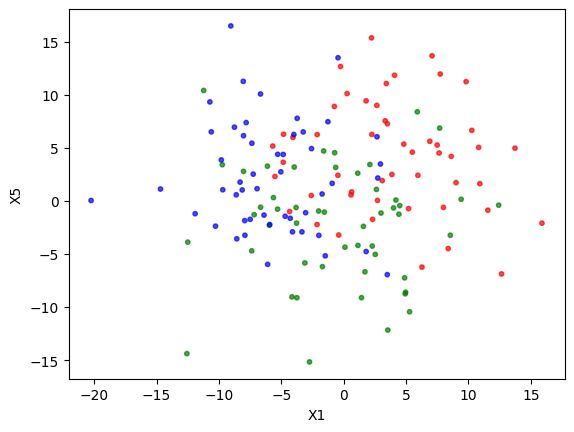

In [25]:
# Visualize on the X1 vs X5 plane. X1 ==> column 0,  X5 ==> column 4.
# We can hardly tell the clusters apart!
# The clusters largely overlap.
plt.scatter(X[:, 0], X[:, 4], marker="o", alpha=0.7, s=10, c=labelColors)
plt.xlabel("X1")
plt.ylabel("X5")
plt.show()

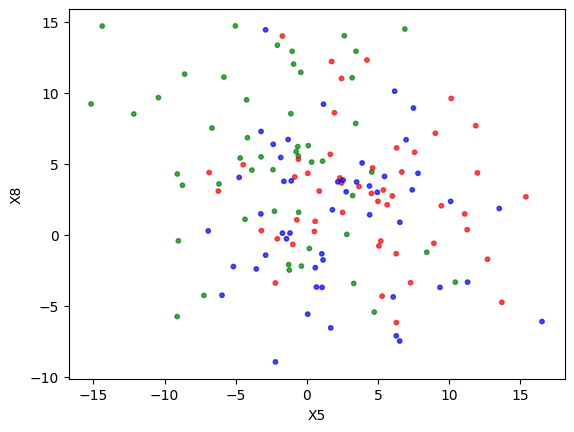

In [26]:
# Visualize on the X5 vs X8 plane. X5 ==> column 4,  X8 ==> column 7.
# We can hardly tell the clusters apart!
# The clusters largely overlap.
plt.scatter(X[:, 4], X[:, 7], marker="o", alpha=0.7, s=10, c=labelColors)
plt.xlabel("X5")
plt.ylabel("X8")
plt.show()

#### 3.2. Visualize on the plane defined by PC1 and PC2:

In [27]:
# Only 2 first PCs are needed.
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X)

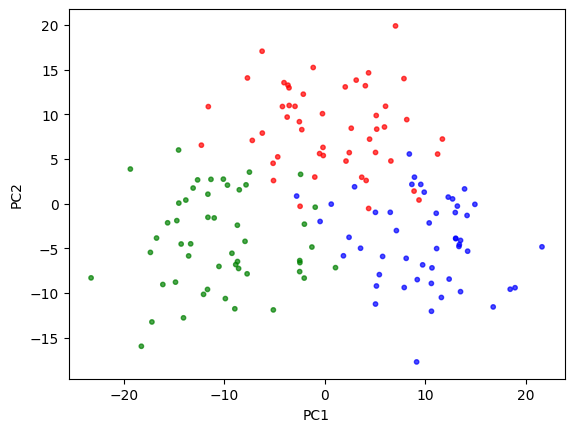

In [28]:
# Visualize on the PC1 vs PC2 plane.
# The clusters overlap the least!
plt.scatter(X_pca[:, 0], X_pca[:, 1], marker="o", alpha=0.7, s=10, c=labelColors)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()